# Anomaly detection in IoT network traffic: v2

**v1's question.** Can malicious connections in an IoT connection log be identified, without relying on labels, from features
engineered out of the raw columns? v1 (a course assignment) concluded "not very accurate": it caught 16 of 21,222 malicious
connections.

**v2 answers the same question on the same data** (capture 34 of the CTU-IoT-Malware dataset), with better methods, and lets the
evidence decide. Then it asks whether the answer travels to other captures.

**Hypothesis, written down before the final numbers (H1).** Malicious connections in capture 34 can be separated from benign ones
without using labels, using features engineered from the raw columns, *and those engineered features are what make it work.*

The v1 notebook is [`ML_unsupervised_learning.ipynb`](ML_unsupervised_learning.ipynb) (tag `v1-coursework`). Everything below is
recomputed when this notebook runs, and it checks itself against `v2/results.json` at the end.

In [1]:
import sys, json
sys.path.insert(0, ".")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import anomaly_features as af
import anomaly_experiment as ex

frames, feats = ex.load_all()
A = ex.study_capture34(frames, feats)          # Part A, about 10 s
print({c: len(f) for c, f in frames.items()}, "connections per capture")
print(f"capture 34: {A['malicious']:,} of {A['connections']:,} malicious ({A['share_malicious']:.0%});", A["labels"])

{'20': 3209, '21': 3286, '42': 4426, '44': 237, '34': 23145, '8': 10403} connections per capture
capture 34: 21,222 of 23,145 malicious (92%); {'Malicious   DDoS': 14394, 'Malicious   C&C': 6706, 'Benign': 1923, 'Malicious   PartOfAHorizontalPortScan': 122}


# Part A: v1's question, on v1's data

## 1. What did v1's detector actually do?

v1 told Isolation Forest that 1% of connections are anomalous. But in this capture **92% are malicious**: the *rare* connections are
the benign ones. So what does "anomalous" select? Score every connection by how unusual it looks, then check which class the
unusual ones belong to:

In [2]:
iso = A["isolation_forest_unsupervised"]
print(f"AUROC of 'how unusual' for spotting malicious: {iso['auroc']:.3f}   (0.5 = coin flip, 0 = perfectly backwards)")
print(f"read the other way round:                       {iso['auroc_if_flipped']:.3f}")

AUROC of 'how unusual' for spotting malicious: 0.052   (0.5 = coin flip, 0 = perfectly backwards)
read the other way round:                       0.948


An AUROC of **0.05** is not a detector that failed to find anything. It is a detector that works *backwards*: the connections it
rates most unusual are overwhelmingly the benign ones, exactly as it was built to do. v1's accuracy of 0.07 was the detector doing its
job on a question it was asked the wrong way round. (Flipping the sign uses the labels to choose a direction, so it is a diagnosis,
not a method. The methods below do not need that.)

## 2. Features

One row per connection. The features leave out three things on purpose: **the labels**; **IP addresses** (an address identifies a
device, and across captures the scenario); **the timestamp**. What is left: sizes and packet counts (log-scaled, with a missing flag),
protocol, connection state, the kind of destination port, and the v1-style engineered feature, **how many connections the same
source opened in the last 10 seconds** (looking only at the past).

In [3]:
X34 = feats["34"]
print(X34.shape[1], "features per connection")
list(X34.columns)

37 features per connection


['log_duration',
 'missing_duration',
 'log_orig_bytes',
 'missing_orig_bytes',
 'log_resp_bytes',
 'missing_resp_bytes',
 'log_orig_pkts',
 'missing_orig_pkts',
 'log_orig_ip_bytes',
 'missing_orig_ip_bytes',
 'log_resp_pkts',
 'missing_resp_pkts',
 'log_resp_ip_bytes',
 'missing_resp_ip_bytes',
 'log_missed_bytes',
 'missing_missed_bytes',
 'recent_conns',
 'history_len',
 'port_well_known',
 'port_registered',
 'port_ephemeral',
 'proto_tcp',
 'proto_udp',
 'proto_icmp',
 'state_S0',
 'state_S1',
 'state_S2',
 'state_S3',
 'state_SF',
 'state_REJ',
 'state_RSTO',
 'state_RSTR',
 'state_RSTOS0',
 'state_RSTRH',
 'state_SH',
 'state_SHR',
 'state_OTH']

## 3. How the methods are scored

- **Cross-validation on contiguous time blocks** (five of them), not random rows: connections arrive in bursts, and a random split puts
  neighbours of one burst on both sides.
- **AUROC** (how well the scores rank malicious above benign) and **average precision**. Accuracy is useless here: "always malicious"
  scores 92%.
- **Recall at a false-alarm budget** (of the malicious connections, how many are caught if only 5% of benign ones may raise an alarm).

## 4. Different methods

**Clustering.** No labels. Group the connections, then name each cluster after its majority class and score that labelling.
Few clusters cannot separate the traffic; four can:

In [4]:
km = pd.DataFrame(A["kmeans"]).T.rename(columns={"adjusted_rand": "adjusted Rand", "balanced_accuracy": "balanced accuracy"}).round(3)
km.index = [f"{k} clusters" for k in km.index]
km

,adjusted Rand,balanced accuracy
2 clusters,0.124,0.500
3 clusters,0.171,0.500
4 clusters,0.246,0.971
6 clusters,0.223,0.971
8 clusters,0.222,0.974


With four clusters the traffic splits by *attack type*: the clusters are almost pure. Each cell below counts connections:

In [5]:
pd.DataFrame(A["kmeans4_composition"]).T.rename_axis("cluster")

,Benign,C&C,DDoS,PartOfAHorizontalPortScan
cluster,,,,
0,30,0,14377,0
1,13,1641,1,0
2,68,5065,16,121
3,1812,0,0,1


Cluster 0 is the DDoS flood, cluster 3 is benign traffic, clusters 1 and 2 are command-and-control (cluster 2 also holds the port
scan). Unsupervised grouping rediscovers the attack types without ever seeing a label.

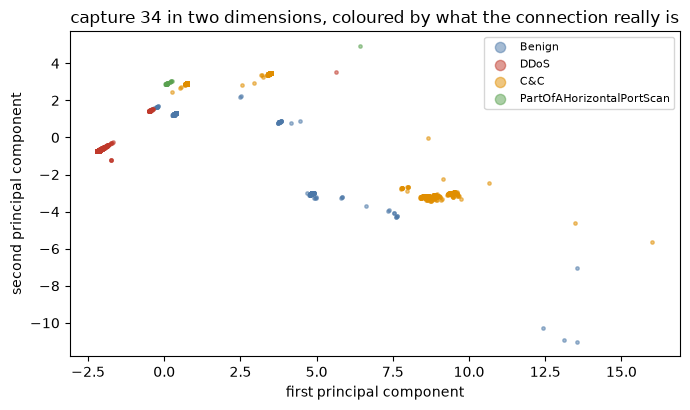

In [6]:
# What v1 noticed in its projection ("a cluster of anomalies that lies on a line"): project and colour by attack
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
df34 = frames["34"]
attack = df34["label"].str.replace("Malicious   ", "", regex=False).str.strip().to_numpy()
Z = PCA(n_components=2, random_state=0).fit_transform(StandardScaler().fit_transform(X34))
idx = np.random.default_rng(0).choice(len(Z), 6000, replace=False)
fig, ax = plt.subplots(figsize=(7, 4.2))
for a, c in zip(["Benign", "DDoS", "C&C", "PartOfAHorizontalPortScan"], ["#4c78a8", "#c0392b", "#e08e00", "#59a14f"]):
    m = attack[idx] == a
    ax.scatter(Z[idx][m, 0], Z[idx][m, 1], s=6, alpha=0.5, color=c, label=a)
ax.set_xlabel("first principal component"); ax.set_ylabel("second principal component"); ax.legend(markerscale=3, fontsize=8)
ax.set_title("capture 34 in two dimensions, coloured by what the connection really is"); plt.tight_layout(); plt.show()

The red streak on the left is the DDoS flood: thousands of near-identical connections that project onto one line. v1's "cluster
of anomalies that lies on a line" is very likely this, though v1's own plot is not reproduced here, so that is an inference. Each
attack is a tight, repetitive group; the benign connections are the scattered ones.

**Novelty detection.** Learn what *normal* looks like from the benign connections only, then score everything else. This is
the version of "anomaly detection" that fits a capture where the bad traffic is the majority. A supervised model is included as a
reference: what the features can support at all.

In [7]:
rows = {"Isolation Forest, benign only": A["novelty_isolation_forest"], "One-class SVM, benign only": A["novelty_one_class_svm"],
        "Supervised reference (uses labels)": A["supervised_reference"]}
pd.DataFrame(rows).T[["auroc", "average_precision", "recall_at_1pct_fpr", "recall_at_5pct_fpr"]].round(3)

,auroc,average_precision,recall_at_1pct_fpr,recall_at_5pct_fpr
"Isolation Forest, benign only",0.945,0.988,0.005,0.296
"One-class SVM, benign only",0.988,0.996,0.038,0.998
Supervised reference (uses labels),0.980,0.995,0.006,0.994


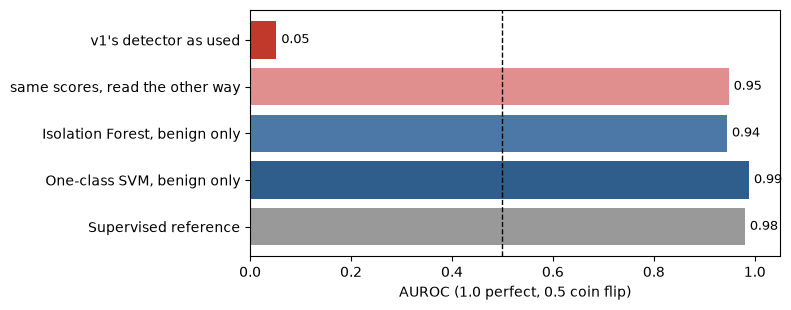

In [8]:
# the headline comparison
bars = [("v1's detector as used", iso["auroc"], "#c0392b"), ("same scores, read the other way", iso["auroc_if_flipped"], "#e08e8e"),
        ("Isolation Forest, benign only", A["novelty_isolation_forest"]["auroc"], "#4c78a8"),
        ("One-class SVM, benign only", A["novelty_one_class_svm"]["auroc"], "#2f5d8c"),
        ("Supervised reference", A["supervised_reference"]["auroc"], "#999")]
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.barh([b[0] for b in bars][::-1], [b[1] for b in bars][::-1], color=[b[2] for b in bars][::-1])
ax.axvline(0.5, color="k", ls="--", lw=1); ax.set_xlim(0, 1.05); ax.set_xlabel("AUROC (1.0 perfect, 0.5 coin flip)")
for i, b in enumerate(bars[::-1]): ax.text(b[1] + 0.01, i, f"{b[1]:.2f}", va="center", fontsize=9)
plt.tight_layout(); plt.show()

Learning "normal" from benign traffic alone separates malicious from benign almost as well as a model that was shown the labels
(0.99 vs 0.98), for every attack type:

In [9]:
{k: round(v, 3) for k, v in A["novelty_one_class_svm_by_attack"].items()}

{'C&C': 0.989, 'DDoS': 0.988, 'PartOfAHorizontalPortScan': 0.99}

One caution: at a *very* strict false-alarm budget (1%) these detectors catch little (see the table above), because the few
benign connections that look odd rank above most attacks. At 5% they catch nearly everything. The cross-validated scores are pooled
across blocks, and two of the five time blocks contain no benign traffic at all, so treat the exact figures as indicative.

## 5. Is it the engineered features? (the second half of H1)

Drop one group of features at a time and re-score the supervised reference. If v1's rolling per-source count were what made detection
possible, removing it should hurt.

In [10]:
ab = pd.DataFrame(A["ablation"]).T[["auroc", "average_precision", "recall_at_5pct_fpr"]].round(3)
ab.loc["(nothing dropped)"] = pd.Series(A["supervised_reference"])[["auroc", "average_precision", "recall_at_5pct_fpr"]].round(3)
ab.rename_axis("dropped")

,auroc,average_precision,recall_at_5pct_fpr
dropped,,,
the rolling 10-second connection count (v1's feature),0.985,0.998,0.994
byte and packet counts,0.997,1.000,0.994
destination port class,0.987,0.998,0.920
protocol and connection state,0.986,0.998,0.997
(nothing dropped),0.980,0.995,0.994


**It does not.** Removing v1's rolling count changes nothing (0.985 against 0.980 with everything), and removing the byte and
packet counts slightly *helps*. Why so easy? Look at the best single feature, and at what each class connects to:

In [11]:
print("best single features (AUROC):", [(f["feature"], round(f["auroc"], 3)) for f in A["best_single_features"][:3]])
pd.DataFrame(A["top_destination_ports"]).T.rename_axis("class")

best single features (AUROC): [('proto_tcp', 0.971), ('proto_udp', 0.971), ('recent_conns', 0.87)]


,123,53,6667,80,5376,63798,256
class,,,,,,,
Benign,1618.0,233.0,NaN,NaN,NaN,NaN,NaN
C&C,NaN,NaN,6706.0,NaN,NaN,NaN,NaN
DDoS,NaN,NaN,NaN,14393.0,1.0,NaN,NaN
PartOfAHorizontalPortScan,NaN,NaN,NaN,NaN,NaN,121.0,1.0


**The protocol alone** (UDP vs TCP) gets 0.97. The benign traffic in this capture is NTP and DNS (ports 123 and 53, UDP); the
attacks each hit one service: DDoS to web port 80, command-and-control to IRC port 6667, the scan to high ports. A capture with one
lab device and three scripted behaviours is easy to separate with almost any feature. The engineered features are not what is doing
the work.

### Verdict on H1

| Part of the hypothesis | Evidence | Verdict |
|---|---|---|
| Malicious can be separated from benign without labels | clustering reaches 0.97 balanced accuracy with 4 clusters; benign-only novelty detection reaches AUROC 0.94 to 0.99 | **supported** |
| It works because of the engineered features | dropping v1's feature changes nothing; protocol alone gives 0.97 | **not supported** |
| (v1's own conclusion) the approach was inaccurate | the detector worked backwards because the data is 92% malicious; a method that fits the data reaches 0.99 | **not supported**: the method v1 chose did not fit the data |

# Part B: does it travel?

A capture this easy raises the obvious worry: would anything learned here survive contact with different traffic?

## 6. Train on capture 34, score the others

In [12]:
T = ex.transfer_from_capture34(frames, feats)
pd.DataFrame(T).T[["connections", "malicious", "auroc", "average_precision", "recall_at_5pct_fpr"]].round(3).rename_axis("capture")

,connections,malicious,auroc,average_precision,recall_at_5pct_fpr
capture,,,,,
20,3209.0,16.0,0.991,0.573,1.000
21,3286.0,14.0,0.981,0.405,0.857
42,4426.0,6.0,0.554,0.002,0.000
44,237.0,26.0,0.991,0.827,1.000
8,10403.0,8222.0,0.999,0.999,1.000


It travels to captures 8, 20, 21 and 44 (AUROC 0.98 to 1.00) and **fails on capture 42** (0.55, about a coin flip). Capture 42's
malicious connections are file downloads, a behaviour capture 34 never contained.

## 7. The setting anomaly detection assumes: mostly benign

Captures 20, 21, 42 and 44 are 89% to 99.9% benign. Hold each out in turn; the unsupervised detectors are fitted on the *other*
three without labels, so they never see the capture they are scored on. The supervised baseline may also train on the labelled
captures 34 and 8.

In [13]:
out, scores = ex.run_experiment(frames, feats, keep_scores=True)
res, order = out["held_out_captures"], ex.BENIGN_DOMINATED
names = {"isolation_forest": "Isolation Forest", "local_outlier_factor": "Local Outlier Factor", "supervised_baseline": "Supervised baseline"}
rows = []
for h in order:
    for m in ex.METHODS:
        rows.append({"capture": f"{h} ({res[h]['malicious']} of {res[h]['connections']:,})", "method": names[m],
                     "average precision": round(res[h][m]["average_precision"], 2),
                     "recall @1% false alarms": round(res[h][m]["recall_at_1pct_fpr"], 2),
                     "recall @5% false alarms": round(res[h][m]["recall_at_5pct_fpr"], 2)})
pd.DataFrame(rows).set_index(["capture", "method"])

average precision  \
capture          method                                    
20 (16 of 3,209) Isolation Forest                   0.29   
                 Local Outlier Factor               0.10   
                 Supervised baseline                0.84   
21 (14 of 3,286) Isolation Forest                   0.34   
                 Local Outlier Factor               0.03   
                 Supervised baseline                0.94   
42 (6 of 4,426)  Isolation Forest                   0.59   
                 Local Outlier Factor               0.00   
                 Supervised baseline                0.00   
44 (26 of 237)   Isolation Forest                   0.94   
                 Local Outlier Factor               0.96   
                 Supervised baseline                0.92   

                                       recall @1% false alarms  \
capture          method                                          
20 (16 of 3,209) Isolation Forest                         0.19   
                 Local Outlier Factor                     0.06   
                 Supervised baseline                      0.94   
21 (14 of 3,286) Isolation Forest                         0.21   
                 Local Outlier Factor                     0.21   
                 Supervised baseline                      1.00   
42 (6 of 4,426)  Isolation Forest                         1.00   
                 Local Outlier Factor                     0.00   
                 Supervised baseline                      0.00   
44 (26 of 237)   Isolation Forest                         1.00   
                 Local Outlier Factor                     0.96   
                 Supervised baseline                      0.58   

                                       recall @5% false alarms  
capture          method                                         
20 (16 of 3,209) Isolation Forest                         1.00  
                 Local Outlier Factor                     0.38  
                 Supervised baseline                      0.94  
21 (14 of 3,286) Isolation Forest                         1.00  
                 Local Outlier Factor                     0.21  
                 Supervised baseline                      1.00  
42 (6 of 4,426)  Isolation Forest                         1.00  
                 Local Outlier Factor                     0.00  
                 Supervised baseline                      0.00  
44 (26 of 237)   Isolation Forest                         1.00  
                 Local Outlier Factor                     1.00  
                 Supervised baseline                      1.00

In [14]:
mean = pd.DataFrame(out["mean_over_captures"]).T.rename(index=names).round(2)
mean.loc["Random guessing"] = [round(out["mean_prevalence"], 2), 0.01, 0.05]
mean

,average_precision,recall_at_1pct_fpr,recall_at_5pct_fpr
Isolation Forest,0.54,0.60,1.00
Local Outlier Factor,0.27,0.31,0.40
Supervised baseline,0.68,0.63,0.73
Random guessing,0.03,0.01,0.05


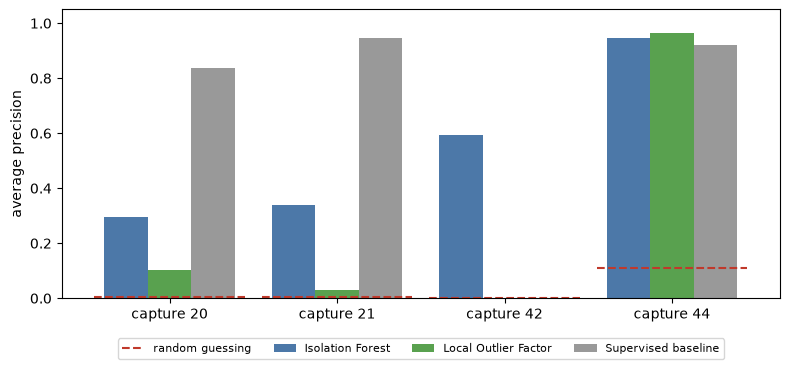

In [15]:
fig, ax = plt.subplots(figsize=(8, 3.8)); w = 0.26; x = np.arange(len(order))
for i, m in enumerate(ex.METHODS):
    ax.bar(x + (i - 1) * w, [res[h][m]["average_precision"] for h in order], w, label=names[m], color=["#4c78a8", "#59a14f", "#999"][i])
for j, h in enumerate(order):
    ax.hlines(res[h]["prevalence"], j - 0.45, j + 0.45, colors="#c0392b", linestyles="--", label="random guessing" if j == 0 else None)
ax.set_xticks(x); ax.set_xticklabels([f"capture {h}" for h in order]); ax.set_ylabel("average precision"); ax.set_ylim(0, 1.05)
ax.legend(fontsize=8, ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.12)); plt.tight_layout(); plt.show()

In [16]:
for h in order:
    r = res[h]
    print(f"capture {h}: attacks {r['attack_types']}\n"
          f"   recall @1% false alarms: isolation forest {r['isolation_forest']['recall_at_1pct_fpr']:.2f}, "
          f"supervised {r['supervised_baseline']['recall_at_1pct_fpr']:.2f}")

capture 20: attacks {'Torii': 16}
   recall @1% false alarms: isolation forest 0.19, supervised 0.94
capture 21: attacks {'Torii': 14}
   recall @1% false alarms: isolation forest 0.21, supervised 1.00
capture 42: attacks {'': 3, 'FileDownload': 3}
   recall @1% false alarms: isolation forest 1.00, supervised 0.00
capture 44: attacks {'': 15, 'FileDownload': 11}
   recall @1% false alarms: isolation forest 1.00, supervised 0.58


In the setting anomaly detection is built for, Isolation Forest with no labels ranks the malicious connections far above chance on
captures it never saw, and at a 5% false-alarm budget catches every one of them in all four. Labels help only for attacks the model
has seen: the supervised baseline is excellent on the Torii captures (0.94 and 1.00) and finds **nothing** in capture 42, where the
unsupervised detector finds everything. Local Outlier Factor is clearly worse.

# Conclusion

1. **v1's question has a clear answer: yes.** Malicious connections in this capture can be identified without labels, by clustering
   or by learning normal traffic from benign connections only (AUROC up to 0.99).
2. **v1's method failed for a specific, avoidable reason:** it asked an anomaly detector to find a majority class. The detector
   worked backwards (AUROC 0.05), not randomly.
3. **The engineered features were not the point.** Protocol alone gives 0.97 on this capture, and removing v1's rolling-count
   feature changes nothing. The lesson is to check how easy the data is before crediting the features.
4. **It partly generalises.** What was learned from capture 34 transfers to four of five other captures, and fails on a different kind
   of attack (file download). In the mostly-benign setting an unsupervised detector catches all of it at a 5% false-alarm budget.

# Limits

- Capture 34 is one lab capture with one benign pattern and three scripted attacks. "Easy" is a property of the data, not of the
  method, and nothing here says how it would do on a real network.
- Malicious counts in captures 20, 21, 42 and 44 are tiny (6 to 26), so Part B differences between methods are not conclusive.
- Part A cross-validated scores are pooled across blocks, two of which have no benign traffic; strict-budget recall is fragile.
- Training samples are capped at 20,000 rows per capture.

# Reproduce

```bash
scripts/fetch-data.sh
.venv/bin/python v2/run.py                      # results.json and the figures
.venv/bin/python v2/build_notebook.py           # this notebook, executed
```

In [17]:
# consistency check: the notebook and v2/run.py agree
saved = json.load(open("v2/results.json"))
assert saved["mean_over_captures"] == out["mean_over_captures"], "Part B disagrees with v2/results.json"
assert saved["same_data_capture_34"]["supervised_reference"] == A["supervised_reference"], "Part A disagrees with v2/results.json"
assert saved["transfer_from_capture_34"] == T, "transfer disagrees with v2/results.json"
print("matches v2/results.json")

matches v2/results.json
